In [ ]:
Problem Statement:

Build an end-to-end machine learning classification pipeline to predict agricultural risk tiers 
(risk_category) from 75,000 farm records, handling class imbalance to enable targeted, proactive 
interventions against crop failure.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv(r"C:\Users\Prashanth Reddy\Desktop\modern_agriculture_ai_crop_production_2020_2050.csv")

In [3]:
df.head()

,record_id,year,region,country,crop,farm_size_hectares,farm_type,soil_type,irrigation_type,ai_system_used,...,production_tons,operational_cost_usd_per_ha,market_price_usd_per_ton,revenue_usd,profit_usd,carbon_emission_kgco2e_per_ha,sustainability_score,yield_forecast_next_year_ton_per_ha,risk_category,recommended_action
0,1,2035,South America,Chile,Dates,40.78,Semi-Mechanized,Peaty,Rainfed,NaN,...,330.32,1059.23,196.12,64782.36,21586.96,646.75,54.25,8.38,Moderate,Start with IoT soil sensors and basic AI analy...
1,2,2038,Middle East,Turkey,Potato,17.04,Traditional,Silty,Smart Drip,NaN,...,422.59,1017.69,442.65,187059.46,169718.02,948.05,28.77,24.56,Moderate,Start with IoT soil sensors and basic AI analy...
2,3,2036,Africa,Egypt,Mango,119.06,Smart AI Farm,Loam,Drip,AI Irrigation Agent,...,1382.29,1479.36,463.90,641244.33,465111.73,1062.54,57.07,11.81,Moderate,Maintain current smart farming plan
3,4,2031,Europe,Germany,Rice,23.15,Semi-Mechanized,Silty,Flood Irrigation,Yield Prediction ML,...,126.86,1088.85,375.24,47602.95,22396.07,672.48,54.67,5.60,Moderate,Shift to drip or smart irrigation
4,5,2029,South America,Colombia,Sugarcane,22.03,Semi-Mechanized,Silty,Drip,Basic Analytics,...,1441.42,870.99,198.97,286799.34,267611.43,516.42,44.15,72.07,Moderate,Deploy pest monitoring traps and precision spr...


In [4]:
df.tail()

,record_id,year,region,country,crop,farm_size_hectares,farm_type,soil_type,irrigation_type,ai_system_used,...,production_tons,operational_cost_usd_per_ha,market_price_usd_per_ton,revenue_usd,profit_usd,carbon_emission_kgco2e_per_ha,sustainability_score,yield_forecast_next_year_ton_per_ha,risk_category,recommended_action
74995,74996,2028,East Asia,China,Tomato,7.15,Traditional,Loam,Drip,AI Irrigation Agent,...,272.99,1133.06,349.76,95480.98,87379.60,1021.35,73.85,38.10,Moderate,Maintain current smart farming plan
74996,74997,2050,Southeast Asia,Philippines,Mango,34.60,Smart AI Farm,Clay,Flood Irrigation,Computer Vision,...,341.50,978.76,803.09,274255.24,240390.14,646.29,45.46,9.85,Moderate,Maintain current smart farming plan
74997,74998,2022,North America,United States,Mango,7.88,Semi-Mechanized,Peaty,Rainfed,AI Disease Detection,...,68.79,1155.21,400.01,27516.69,18413.64,708.00,60.90,8.59,Moderate,Deploy pest monitoring traps and precision spr...
74998,74999,2023,North America,United States,Dates,9.80,Greenhouse,Sandy,Sprinkler,NaN,...,71.83,1010.17,194.16,13946.51,4046.84,1068.54,43.39,7.94,Moderate,Start with IoT soil sensors and basic AI analy...
74999,75000,2042,North America,Mexico,Cotton,15.21,Smart AI Farm,Loam,Flood Irrigation,Computer Vision,...,37.11,1423.44,429.64,15943.94,-5706.58,1206.18,29.39,2.39,Moderate,Maintain current smart farming plan


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 36 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   record_id                            75000 non-null  int64  
 1   year                                 75000 non-null  int64  
 2   region                               75000 non-null  object 
 3   country                              75000 non-null  object 
 4   crop                                 75000 non-null  object 
 5   farm_size_hectares                   75000 non-null  float64
 6   farm_type                            75000 non-null  object 
 7   soil_type                            75000 non-null  object 
 8   irrigation_type                      75000 non-null  object 
 9   ai_system_used                       60019 non-null  object 
 10  technology_stack                     75000 non-null  object 
 11  ai_adoption_score           

In [6]:
df.describe()

,record_id,year,farm_size_hectares,ai_adoption_score,mechanization_index,iot_sensor_density_per_ha,drone_usage_hours_per_month,satellite_monitoring_score,avg_temperature_c,annual_rainfall_mm,...,pest_risk_score,yield_ton_per_ha,production_tons,operational_cost_usd_per_ha,market_price_usd_per_ton,revenue_usd,profit_usd,carbon_emission_kgco2e_per_ha,sustainability_score,yield_forecast_next_year_ton_per_ha
count,75000.000000,75000.000000,75000.000000,75000.000000,75000.00000,75000.000000,75000.000000,75000.00000,75000.000000,75000.000000,...,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,7.500000e+04,7.500000e+04,75000.000000,75000.000000,75000.000000
mean,37500.500000,2034.956960,26.904183,52.687583,50.00591,7.879769,4.088757,48.57339,27.003973,651.015669,...,56.147373,17.143192,464.752589,1142.224057,369.217361,1.730197e+05,1.422762e+05,881.892716,50.464996,17.470732
std,21650.779432,8.927437,17.763317,20.301630,16.48017,5.201213,4.101138,23.95471,5.503631,275.632315,...,13.867417,21.336471,763.413926,183.233849,128.989871,2.853632e+05,2.776223e+05,202.495492,10.999204,21.788411
min,1.000000,2020.000000,0.640000,0.000000,0.00000,0.000000,0.000000,0.00000,7.670000,50.000000,...,0.000000,1.070000,1.910000,437.580000,80.000000,3.943500e+02,-1.090541e+05,116.300000,1.370000,1.030000
25%,18750.750000,2027.000000,13.797500,36.730000,38.20750,3.710000,0.780000,30.20000,23.140000,460.940000,...,46.760000,3.590000,72.310000,1016.940000,281.370000,2.294408e+04,-1.018800e+02,742.800000,43.200000,3.660000
50%,37500.500000,2035.000000,23.100000,51.780000,49.53500,6.820000,2.840000,47.23000,26.970000,648.140000,...,56.140000,6.260000,158.150000,1140.720000,354.660000,5.593097e+04,2.211739e+04,880.845000,50.640000,6.390000
75%,56250.250000,2043.000000,35.830000,68.180000,61.43000,11.070000,6.230000,66.21000,30.760000,836.000000,...,65.570000,25.500000,476.405000,1266.462500,438.672500,1.898802e+05,1.602331e+05,1018.362500,57.940000,25.920000
max,75000.000000,2050.000000,193.600000,100.000000,100.00000,27.970000,20.840000,100.00000,46.920000,1906.850000,...,100.000000,105.910000,11618.070000,1918.650000,993.570000,4.189128e+06,4.043669e+06,1795.540000,93.660000,112.870000


In [7]:
df.shape

(75000, 36)

In [8]:
df.isnull().sum()

record_id                                  0
year                                       0
region                                     0
country                                    0
crop                                       0
farm_size_hectares                         0
farm_type                                  0
soil_type                                  0
irrigation_type                            0
ai_system_used                         14981
technology_stack                           0
ai_adoption_score                          0
mechanization_index                        0
iot_sensor_density_per_ha                  0
drone_usage_hours_per_month                0
satellite_monitoring_score                 0
avg_temperature_c                          0
annual_rainfall_mm                         0
soil_moisture_percent                      0
fertilizer_kg_per_ha                       0
pesticide_litre_per_ha                     0
water_use_m3_per_ha                        0
climate_st

In [9]:
df[df['ai_system_used'].isnull()][['ai_adoption_score', 'technology_stack']].describe()

,ai_adoption_score
count,14981.000000
mean,29.099363
std,9.608022
min,0.000000
25%,22.390000
50%,28.960000
75%,35.780000
max,63.980000


In [10]:
df['ai_system_used'] = df['ai_system_used'].replace(np.nan, 'None / Unspecified')

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
print(df['risk_category'].value_counts())
print(df['risk_category'].value_counts(normalize=True) * 100)

risk_category
Moderate    59056
High        12754
Low          3070
Critical      120
Name: count, dtype: int64
risk_category
Moderate    78.741333
High        17.005333
Low          4.093333
Critical     0.160000
Name: proportion, dtype: float64


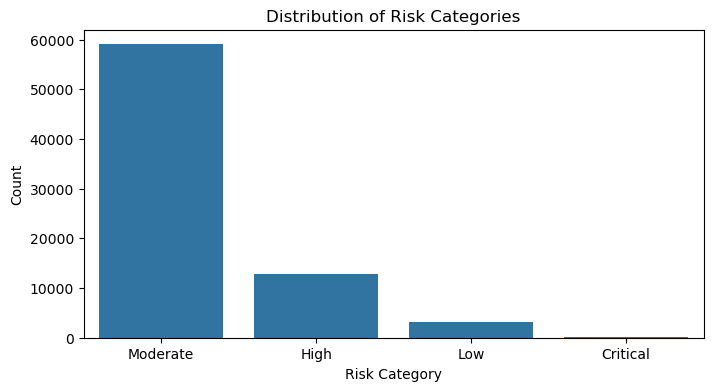

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='risk_category', order=df['risk_category'].value_counts().index)
plt.title('Distribution of Risk Categories')
plt.xlabel('Risk Category')
plt.ylabel('Count')
plt.show()

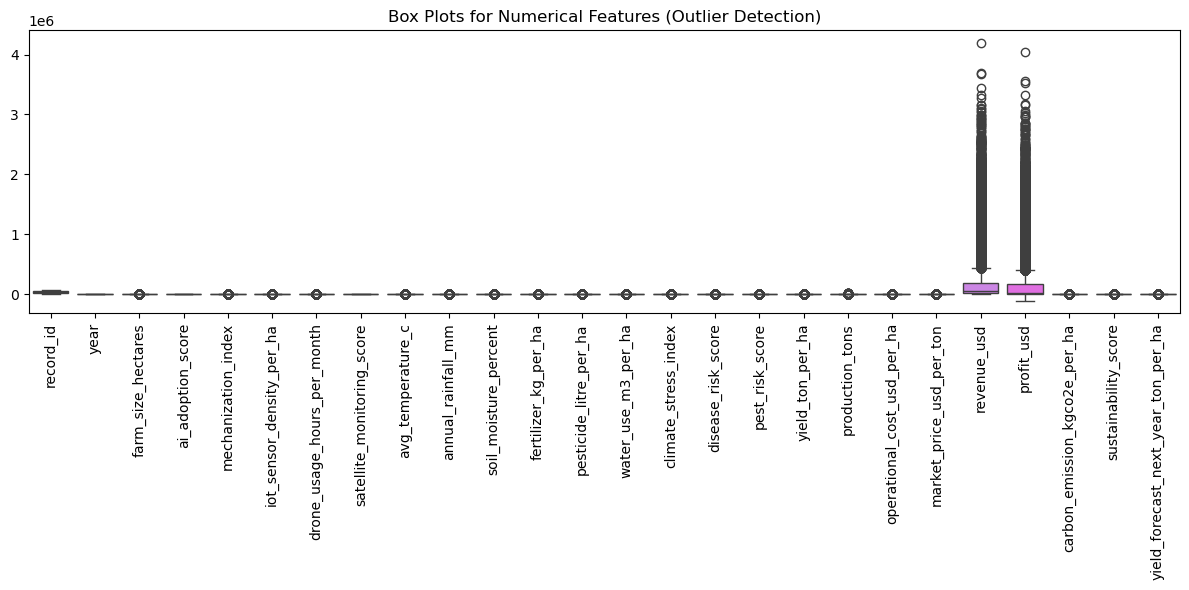

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns from the main dataframe
numerical_cols = df.select_dtypes(include=['number']).columns

# Plot box plots for each numerical feature
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numerical_cols])
plt.xticks(rotation=90)
plt.title("Box Plots for Numerical Features (Outlier Detection)")
plt.tight_layout()
plt.show()

In [17]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Define features (X) and target (y)
target_col = 'risk_category'
X = df.drop(columns=[target_col])
y = df[target_col]

# 2. Stratified train-test split (preserves rare Critical class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [18]:
# 3. Combine training set temporarily to filter outliers strictly on train data
train_df = pd.concat([X_train, y_train], axis=1)

# 4. Select numerical columns for IQR outlier detection
numerical_cols = X_train.select_dtypes(include=[np.number]).columns

# 5. Compute IQR bounds on training data
Q1 = train_df[numerical_cols].quantile(0.25)
Q3 = train_df[numerical_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 6. Remove outlier rows from training set
mask = ~((train_df[numerical_cols] < lower_bound) | (train_df[numerical_cols] > upper_bound)).any(axis=1)
train_clean = train_df[mask]

# 7. Final cleaned training arrays
X_train_clean = train_clean.drop(columns=[target_col])
y_train_clean = train_clean[target_col]

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate numeric and categorical feature columns
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

models = {
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'SVC': SVC(class_weight='balanced', random_state=42),
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
}

pipelines = {
    name: Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    for name, model in models.items()
}

In [21]:
for name, pipeline in pipelines.items():
    print(f"=== {name} Pipeline ===")
    display(pipeline)
    print("\n")

=== Decision Tree Pipeline ===


,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True




=== Random Forest Pipeline ===


,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True




=== SVC Pipeline ===


,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True




=== Logistic Regression Pipeline ===


,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [23]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, recall_score

In [24]:
# Decision Tree
dt_pipeline = pipelines['Decision Tree']
dt_pipeline.fit(X_train, y_train)
y_pred_dt = dt_pipeline.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.9646666666666667
              precision    recall  f1-score   support

    Critical       0.60      0.50      0.55        24
        High       0.94      0.92      0.93      2551
         Low       0.85      0.84      0.85       614
    Moderate       0.98      0.98      0.98     11811

    accuracy                           0.96     15000
   macro avg       0.84      0.81      0.83     15000
weighted avg       0.96      0.96      0.96     15000



In [25]:
import warnings
warnings.filterwarnings('ignore')

In [26]:
# Random Forest
rf_pipeline = pipelines['Random Forest']
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9192666666666667
              precision    recall  f1-score   support

    Critical       0.00      0.00      0.00        24
        High       0.94      0.75      0.84      2551
         Low       0.99      0.26      0.41       614
    Moderate       0.92      0.99      0.95     11811

    accuracy                           0.92     15000
   macro avg       0.71      0.50      0.55     15000
weighted avg       0.92      0.92      0.91     15000



In [27]:
# SVC
svc_pipeline = pipelines['SVC']
svc_pipeline.fit(X_train, y_train)
y_pred_svc = svc_pipeline.predict(X_test)

print("SVC Accuracy:", accuracy_score(y_test, y_pred_svc))
print(classification_report(y_test, y_pred_svc))

SVC Accuracy: 0.9648
              precision    recall  f1-score   support

    Critical       0.93      0.54      0.68        24
        High       0.88      1.00      0.94      2551
         Low       0.78      0.99      0.88       614
    Moderate       1.00      0.96      0.98     11811

    accuracy                           0.96     15000
   macro avg       0.90      0.87      0.87     15000
weighted avg       0.97      0.96      0.97     15000



In [28]:
# Logistic Regression
lr_pipeline = pipelines['Logistic Regression']
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.9783333333333334
              precision    recall  f1-score   support

    Critical       0.67      0.92      0.77        24
        High       0.94      1.00      0.97      2551
         Low       0.81      1.00      0.89       614
    Moderate       1.00      0.97      0.99     11811

    accuracy                           0.98     15000
   macro avg       0.85      0.97      0.90     15000
weighted avg       0.98      0.98      0.98     15000



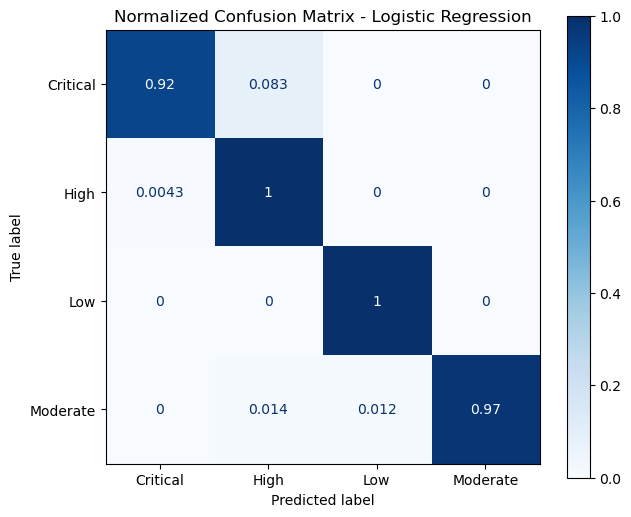

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_lr, 
    cmap='Blues', 
    normalize='true', 
    ax=ax
)
plt.title('Normalized Confusion Matrix - Logistic Regression')
plt.show()

In [30]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    lr_pipeline, 
    X, 
    y, 
    cv=cv, 
    scoring='f1_macro'
)

print("Macro F1 Scores across folds:", cv_scores)
print("Mean Macro F1 Score:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Macro F1 Scores across folds: [0.88667275 0.91852433 0.91451622 0.89014931 0.88820452]
Mean Macro F1 Score: 0.8996134270357536
Standard Deviation: 0.013906182494790057


In [31]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'classifier__C': [0.01, 0.1, 1.0, 10.0],
    'classifier__solver': ['lbfgs', 'saga']
}

grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Macro F1:", grid_search.best_score_)

Best Parameters: {'classifier__C': 10.0, 'classifier__solver': 'lbfgs'}
Best Cross-Validation Macro F1: 0.9330641379795572


In [34]:
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import classification_report

# 1. Initialize a Random Forest pipeline (or ensemble model)
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])

# 2. Train the model
rf_pipeline.fit(X_train, y_train)

# 3. Evaluate predictions
y_pred_rf = rf_pipeline.predict(X_test)
print(classification_report(y_test, y_pred_rf, zero_division=0))

              precision    recall  f1-score   support

    Critical       0.00      0.00      0.00        24
        High       0.94      0.80      0.86      2551
         Low       0.99      0.26      0.42       614
    Moderate       0.92      0.99      0.96     11811

    accuracy                           0.93     15000
   macro avg       0.71      0.51      0.56     15000
weighted avg       0.93      0.93      0.92     15000



In [32]:
best_model = grid_search.best_estimator_

# Option 1: Test with the first 5 samples from your unseen test set
sample_data = X_test.iloc[:5]
sample_predictions = best_model.predict(sample_data)

print("Predictions:", sample_predictions)
print("Actual values:", y_test.iloc[:5].values)

Predictions: ['Moderate' 'Moderate' 'Moderate' 'Moderate' 'Moderate']
Actual values: ['Moderate' 'Moderate' 'Moderate' 'Moderate' 'Moderate']


In [33]:
from sklearn.metrics import classification_report

y_pred_all = best_model.predict(X_test)
print(classification_report(y_test, y_pred_all, zero_division=0))

              precision    recall  f1-score   support

    Critical       0.81      0.92      0.86        24
        High       0.97      1.00      0.98      2551
         Low       0.90      1.00      0.95       614
    Moderate       1.00      0.99      0.99     11811

    accuracy                           0.99     15000
   macro avg       0.92      0.98      0.95     15000
weighted avg       0.99      0.99      0.99     15000

